In [1]:
%pip install numpy tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot  as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers  import Conv2D,Dense,MaxPool2D,Flatten
from tensorflow.keras.models import Sequential, Model
   

In [3]:
digits = load_digits()

In [4]:
X= digits.images.reshape(-1,8,8,1).astype('float32')/16.0
Y= digits.target

In [5]:
X_train,X_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42, stratify=Y)

In [8]:
model = Sequential()
model.add(Conv2D(8,(3,3),activation='relu' , padding ='same' , input_shape=(8,8,1)))
model.add(MaxPool2D((2,2)))

model.add(Conv2D(16,(3,3),activation='relu' , padding ='same' ))
model.add(MaxPool2D((2,2)))

model.add(Flatten())

model.add(Dense(32,activation='relu'))

model.add(Dense(10,activation='softmax'))

C:\Users\LENOVO\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 8)        │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 16)       │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,658 (14.29 KB)

 Trainable params: 3,658 (14.29 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [12]:
model.fit(X_train,y_train, epochs=15, validation_split= 0.1, batch_size=16)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2119 - loss: 2.2364 - val_accuracy: 0.4444 - val_loss: 2.1326
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5189 - loss: 1.8547 - val_accuracy: 0.6736 - val_loss: 1.4802
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7927 - loss: 1.0779 - val_accuracy: 0.8958 - val_loss: 0.7218
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8763 - loss: 0.5674 - val_accuracy: 0.8889 - val_loss: 0.4857
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9049 - loss: 0.3729 - val_accuracy: 0.9236 - val_loss: 0.3209
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9219 - loss: 0.2855 - val_accuracy: 0.9236 - val_loss: 0.2662
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9420 - loss: 0.2264 - val_accuracy: 0.9444 - val_loss: 0.2096
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9513 - loss: 0.1888 - val_accuracy: 0.9375 - val_loss

In [13]:
loss, accuracy =model.evaluate(X_test,y_test)
print('Test Accuracy', accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9556 - loss: 0.1167
Test Accuracy 0.9555555582046509


In [14]:
sample_image = X_test[0:1]
 
layer_outputs = [layer.output for layer in model.layers[:2]]
activation_model = Model(inputs=model.inputs, outputs=layer_outputs)
activations = activation_model.predict(sample_image)
 
first_layer_activation = activations[0]
print("First conv layer output shape:", first_layer_activation.shape)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
First conv layer output shape: (1, 8, 8, 8)


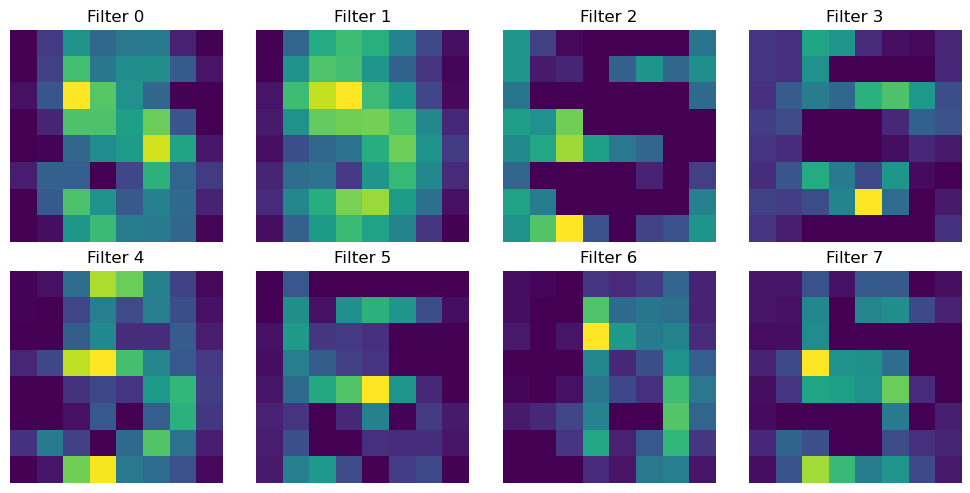

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(10,5))
for i, ax in enumerate(axes.flat):
    ax.imshow(first_layer_activation[0, :, :, i], cmap="viridis")
    ax.set_title(f"Filter {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()
